# Legal Document RAG

**Rishabh Jain**

* This project answers contract questions using retrieved clauses and source citations.
* Charts and evaluation scores come from the saved run.
* See the [project README](../README.md) for setup and the [walkthrough](../docs/walkthrough.md) for process diagrams.
* The data comes from the [LegalBench-RAG](https://github.com/zeroentropy-ai/legalbenchrag) benchmark. Dataset files and API credentials stay local.

## 1. Configure the environment

Install the root requirements and select the Python 3.12 kernel. The notebook supports execution from the repository root or this `notebooks` directory.

In [ ]:
import os, re, json, time, random, warnings, asyncio, inspect
from pathlib import Path
from unicodedata import normalize
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

import nltk
from dotenv import load_dotenv
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity

from langchain_community.document_loaders import DirectoryLoader, TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda, RunnableParallel, RunnablePassthrough
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_chroma import Chroma

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE_DIR = Path.cwd()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent
DATA_DIR = BASE_DIR / "data" / "rag_legal"
CORPUS_DIR, BENCH_DIR = DATA_DIR / "corpus", DATA_DIR / "benchmarks"
nfc = lambda s: normalize("NFC", s)

CHROMA_DIR = BASE_DIR / "chroma_legal_db"

CHUNK_SIZE, CHUNK_OVERLAP = 1500, 200
TOP_K = 5
EMBEDDING_MODEL, LLM_MODEL = "text-embedding-3-small", "gpt-4o-mini"
print(f"chunk_size={CHUNK_SIZE}, overlap={CHUNK_OVERLAP}, top_k={TOP_K}, embeddings={EMBEDDING_MODEL}, llm={LLM_MODEL}")

chunk_size=1500, overlap=200, top_k=5, embeddings=text-embedding-3-small, llm=gpt-4o-mini


## 2. Load and prepare the corpus

Place the corpus and benchmark files under `data/rag_legal`. The cleaner keeps legal wording for retrieval and a separate token representation for EDA.

In [ ]:
def load_corpus(corpus_dir: Path):
    """Load text files with encoding fallback and record metadata and loading errors."""
    documents, errors = [], []
    for cat_dir in sorted(p for p in corpus_dir.iterdir() if p.is_dir()):
        expected = len(list(cat_dir.glob("*.txt")))
        loader = DirectoryLoader(str(cat_dir), glob="*.txt", loader_cls=TextLoader,
                                 loader_kwargs={"encoding": "utf-8", "autodetect_encoding": True},
                                 silent_errors=True)
        loaded = loader.load()
        if len(loaded) < expected:
            errors.append((cat_dir.name, f"{expected - len(loaded)} file(s) could not be decoded and were skipped"))
        for doc in loaded:
            path = Path(doc.metadata["source"])
            if not doc.page_content.strip():
                errors.append((str(path), "empty file - skipped"))
                continue
            doc.metadata.update(category=cat_dir.name, file_name=path.name,
                                file_path=nfc(f"{cat_dir.name}/{path.name}"),
                                n_chars=len(doc.page_content))
            documents.append(doc)
    documents.sort(key=lambda d: d.metadata["file_path"])
    return documents, errors

documents, load_errors = load_corpus(CORPUS_DIR)
print(f"Loaded {len(documents)} documents; problems logged: {load_errors or 'none'}")
docs_df = pd.DataFrame([d.metadata for d in documents])
display(docs_df.groupby("category").agg(documents=("file_name", "count"), total_chars=("n_chars", "sum")))

doc_text = {d.metadata["file_path"]: d.page_content for d in documents}

display(Markdown(
    "* The supplied dataset must already be extracted to `data/rag_legal`.\n"
    "* Each document retains its file path and category for retrieval and source citations.\n"
    "* The loader normalises line endings and records unreadable or empty files."
))

Loaded 644 documents; problems logged: none


,documents,total_chars
category,,
contractnli,93,998437
cuad,431,22602498
maud,117,40429416
privacy_qa,3,56691


* The supplied dataset must already be extracted to `data/rag_legal`.
* Each document retains its file path and category for retrieval and source citations.
* The loader normalises line endings and records unreadable or empty files.

In [ ]:
CHAR_MAP = str.maketrans({"\u201c": '"', "\u201d": '"', "\u2018": "'", "\u2019": "'",
                          "\u00a0": " ", "\u202f": " ", "\u2009": " ", "\u200b": " ", "\ufeff": " ",
                          "\u037e": ";",
                          "\u2013": "-", "\u2014": "-", "\u2026": ".", "\u2022": "*",
                          "\t": " ", "\f": " ", "\v": " "})
NOISE_PATTERNS = {
    "email":     r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+",
    "url":       r"(?:https?://|www\.)\S+",
    "phone":     r"(?:\+?\d{1,3}[\s.-]?)?\(?\d{3}\)?[\s.-]\d{3}[\s.-]\d{4}\b",
    "separator": r"\.{4,}|_{3,}|-{4,}|={3,}|\*{3,}",
}
NOISE_RE = re.compile("|".join(f"(?P<{k}>{v})" for k, v in NOISE_PATTERNS.items()))
WHITESPACE_RE = re.compile(r"\s+")


def clean_with_offsets(text: str):
    """Return (clean_text, offsets) where offsets[i] is the position in `text` of clean_text[i]."""
    # Replace noise with spaces without shifting the original character positions.
    text = NOISE_RE.sub(lambda m: " " * len(m.group()), text.translate(CHAR_MAP))
    pieces, starts, lengths, is_space = [], [], [], []
    pos = 0
    for m in WHITESPACE_RE.finditer(text):
        if m.start() > pos:
            pieces.append(text[pos:m.start()]); starts.append(pos); lengths.append(m.start() - pos); is_space.append(False)
        ws = m.group()
        rep = "\n\n" if ws.count("\n") >= 2 else ("\n" if "\n" in ws else " ")
        pieces.append(rep); starts.append(m.start()); lengths.append(len(rep)); is_space.append(True)
        pos = m.end()
    if pos < len(text):
        pieces.append(text[pos:]); starts.append(pos); lengths.append(len(text) - pos); is_space.append(False)
    lengths, starts, is_space = np.array(lengths), np.array(starts), np.array(is_space)
    seg = np.repeat(np.arange(len(lengths)), lengths)
    within = np.arange(lengths.sum()) - np.repeat(np.cumsum(lengths) - lengths, lengths)
    offsets = starts[seg] + np.where(is_space[seg], 0, within)
    full = "".join(pieces)
    lead = len(full) - len(full.lstrip())
    clean = full.strip()
    return clean, offsets[lead:lead + len(clean)].astype(np.int32)


nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
STOP_WORDS = set(stopwords.words("english")) | set(ENGLISH_STOP_WORDS)


def eda_tokens_from(text: str):
    """Return lower-case alphabetic tokens without stop words or short tokens."""
    return [t for t in re.sub(r"[^a-z]+", " ", text.lower()).split() if len(t) > 2 and t not in STOP_WORDS]


t0 = time.time()
clean_texts, offset_maps, eda_tokens, noise_stats = {}, {}, {}, []
for doc in documents:
    fp = doc.metadata["file_path"]
    counts = Counter(m.lastgroup for m in NOISE_RE.finditer(doc.page_content.translate(CHAR_MAP)))
    clean, offsets = clean_with_offsets(doc.page_content)
    clean_texts[fp], offset_maps[fp] = clean, offsets
    eda_tokens[fp] = eda_tokens_from(clean)
    noise_stats.append({"category": doc.metadata["category"], "raw_chars": len(doc.page_content),
                        "clean_chars": len(clean), **counts})

clean_documents = [Document(page_content=clean_texts[d.metadata["file_path"]], metadata=dict(d.metadata))
                   for d in documents]

noise_df = pd.DataFrame(noise_stats).fillna(0).groupby("category").sum()
noise_df["chars_removed_%"] = (100 * (1 - noise_df.clean_chars / noise_df.raw_chars)).round(2)
print(f"Cleaned {len(documents)} documents in {time.time() - t0:.0f}s")
display(noise_df.astype({c: int for c in NOISE_PATTERNS if c in noise_df}))

# Check a sample of character offsets against the source text.
fp = "contractnli/CopAcc_NDA-and-ToP-Mentors_2.0_2017.txt"
assert all(clean_texts[fp][i] == doc_text[fp][offset_maps[fp][i]].translate(CHAR_MAP) or clean_texts[fp][i].isspace()
           for i in range(0, len(clean_texts[fp]), 97)), "offset map broken"

display(Markdown(
    "* Retrieval text retains casing and legal wording after noise removal.\n"
    "* EDA uses lower-case alphabetic tokens without stop words.\n"
    "* Character mappings retain the original source positions needed for citations and retrieval evaluation."
))

Cleaned 644 documents in 63s


,raw_chars,clean_chars,separator,email,phone,url,chars_removed_%
category,,,,,,,
contractnli,998437,975855,629,9,8,4,2.26
cuad,22602498,21549008,18901,302,425,290,4.66
maud,40429416,39690359,10612,791,117,633,1.83
privacy_qa,56691,54662,0,10,0,34,3.58


* Retrieval text retains casing and legal wording after noise removal.
* EDA uses lower-case alphabetic tokens without stop words.
* Character mappings retain the original source positions needed for citations and retrieval evaluation.

## 3. Explore document lengths and vocabulary

Compare document lengths, frequent words, and TF-IDF similarity before building the index.

Overall document length (cleaned text):


,chars,words,content_tokens
mean,96692,15248,7517
median,35116,5494,2764
min,1390,219,114
max,981505,156104,76003


By category:


chars                         words                      
            count    mean     min     max count   mean    min     max
category                                                             
contractnli    93   10493    2361   33297    93   1612    378    5173
cuad          431   49998    1390  300236   431   7853    219   50288
maud          117  339234  103596  981505   117  53646  16340  156104
privacy_qa      3   18221    3173   26367     3   2953    519    4243

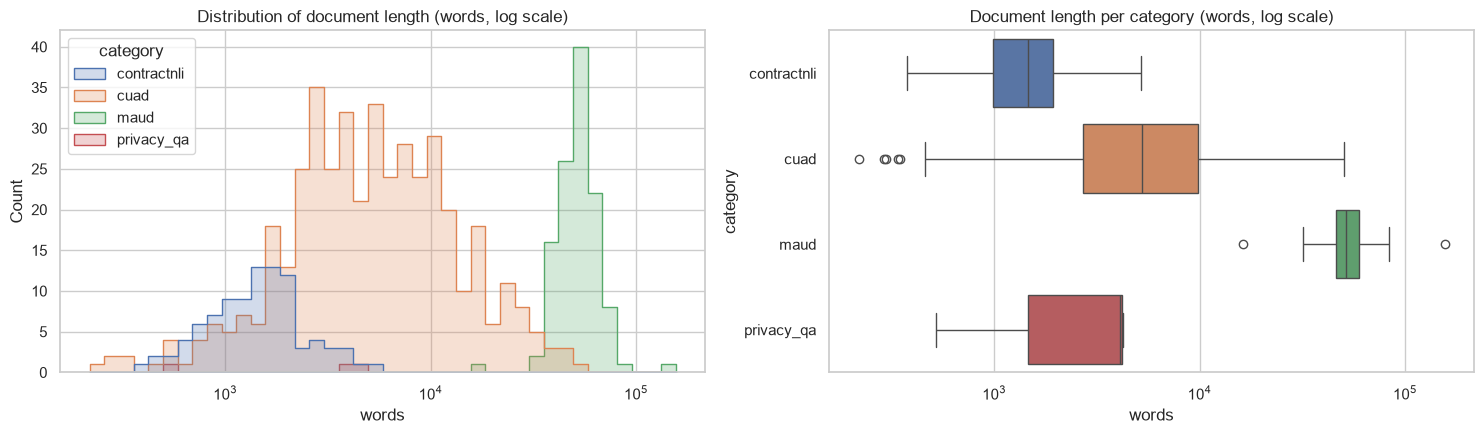

* Mean document length is 15,248 words, compared with a median of 5,494. Long documents raise the mean.
* Length ranges from 219 to 156,104 words. This variation supports splitting documents before retrieval.

In [ ]:
length_df = pd.DataFrame([{"file_path": fp, "category": fp.split("/")[0], "chars": len(clean_texts[fp]),
                           "words": len(clean_texts[fp].split()), "content_tokens": len(eda_tokens[fp])}
                          for fp in clean_texts])

print("Overall document length (cleaned text):")
display(length_df[["chars", "words", "content_tokens"]].agg(["mean", "median", "min", "max"]).round(0).astype(int))
print("By category:")
display(length_df.groupby("category")[["chars", "words"]].agg(["count", "mean", "min", "max"]).round(0).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(data=length_df, x="words", hue="category", log_scale=True, bins=40, ax=axes[0], element="step")
axes[0].set_title("Distribution of document length (words, log scale)")
sns.boxplot(data=length_df, y="category", x="words", hue="category", log_scale=True, ax=axes[1], legend=False)
axes[1].set_title("Document length per category (words, log scale)")
plt.tight_layout(); plt.show()

display(Markdown(
    f"* Mean document length is {length_df.words.mean():,.0f} words, compared with a median of "
    f"{length_df.words.median():,.0f}. Long documents raise the mean.\n"
    f"* Length ranges from {length_df.words.min():,} to {length_df.words.max():,} words. "
    "This variation supports splitting documents before retrieval."
))

,most_common_word,count,least_common_word,count
0,company,135777,aaaaaaaaaa,1
1,shall,95633,aai,1
2,agreement,92941,aaldo,1
3,section,65908,aam,1
4,parent,54884,aarphealthcare,1
5,party,48774,aarpmagazine,1
6,date,34571,aase,1
7,time,31464,abbey,1
8,merger,29835,abbott,1
9,material,29439,abduction,1


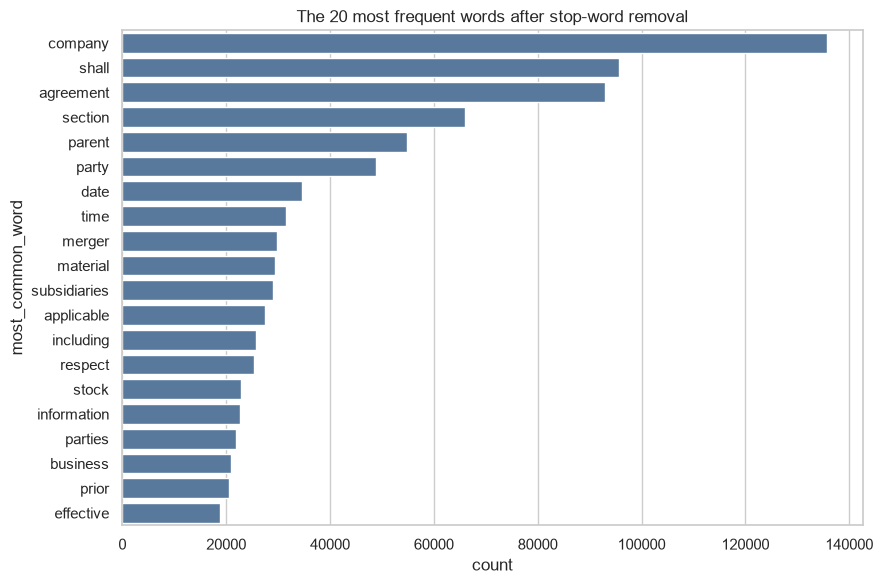

* Common words such as company, shall and agreement reflect legal terminology.
* The least frequent words include names and text artefacts. Tied counts are ordered alphabetically.

In [ ]:
word_freq = Counter(token for tokens in eda_tokens.values() for token in tokens)
most_common = pd.DataFrame(word_freq.most_common(20), columns=["most_common_word", "count"])
least_common = pd.DataFrame(
    sorted(word_freq.items(), key=lambda item: (item[1], item[0]))[:20],
    columns=["least_common_word", "count"],
)
display(pd.concat([most_common, least_common], axis=1))
plt.figure(figsize=(9, 6))
sns.barplot(data=most_common, y="most_common_word", x="count", color="#4C78A8")
plt.title("The 20 most frequent words after stop-word removal")
plt.tight_layout()
plt.show()
display(Markdown(
    "* Common words such as company, shall and agreement reflect legal terminology.\n"
    "* The least frequent words include names and text artefacts. Tied counts are ordered alphabetically."
))

TF-IDF matrix: (644, 14310)


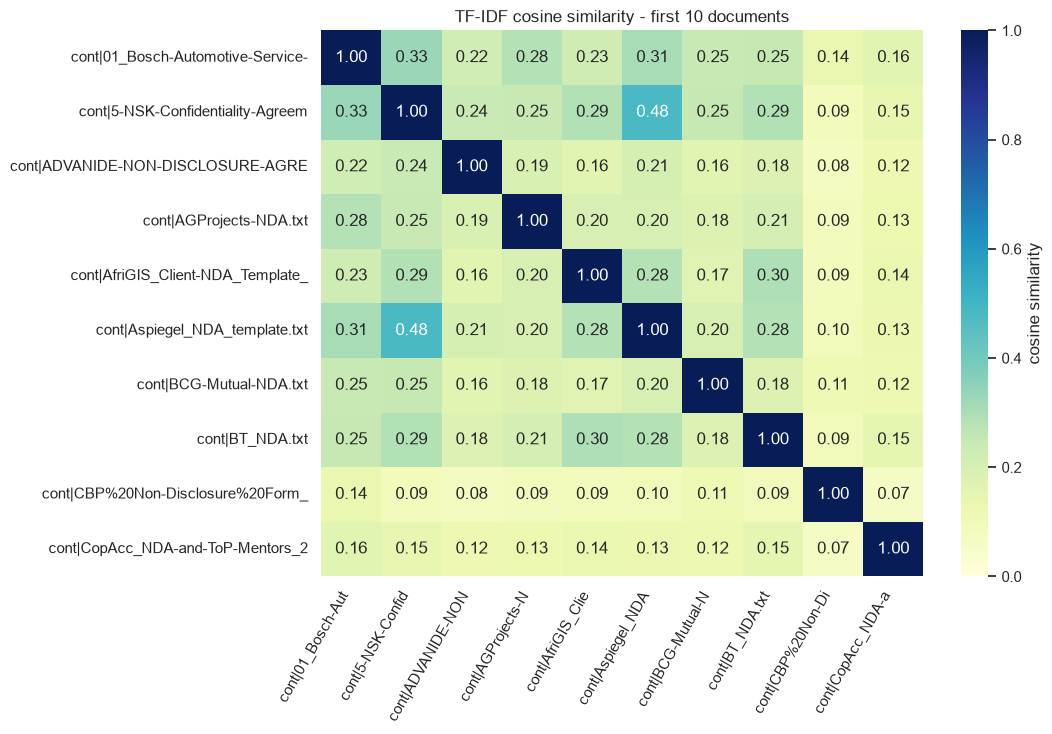

mean off-diagonal similarity = 0.19, max = 0.48


In [ ]:
file_paths = list(clean_texts)
tfidf = TfidfVectorizer(min_df=2, max_df=0.95, sublinear_tf=True, max_features=50_000)
tfidf_matrix = tfidf.fit_transform([" ".join(eda_tokens[fp]) for fp in file_paths])
print("TF-IDF matrix:", tfidf_matrix.shape)

full_sim = cosine_similarity(tfidf_matrix)

def short(fp, n=28):
    cat, name = fp.split("/", 1)
    return f"{cat[:4]}|{name[:n]}"

def plot_sim(idx, title):
    sim = pd.DataFrame(full_sim[np.ix_(idx, idx)], index=[short(file_paths[i]) for i in idx],
                       columns=[short(file_paths[i], 12) for i in idx])
    plt.figure(figsize=(11, 7.5))
    sns.heatmap(sim, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, cbar_kws={"label": "cosine similarity"})
    plt.title(title); plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()
    off_diag = sim.values[~np.eye(len(idx), dtype=bool)]
    print(f"mean off-diagonal similarity = {off_diag.mean():.2f}, max = {off_diag.max():.2f}")

plot_sim(list(range(10)), "TF-IDF cosine similarity - first 10 documents")

In [ ]:
rng = np.random.default_rng(SEED)
random_idx = sorted(rng.choice(len(file_paths), size=10, replace=False).tolist())
print(random_idx)
print([file_paths[i] for i in random_idx])

[55, 56, 60, 129, 276, 280, 416, 447, 492, 549]
['contractnli/QEP-Williston-Form-of-Confidentiality-Agreement-BMO.txt', 'contractnli/QuickBooks-NDA-template.txt', 'contractnli/SE_NDCA_and_PRE-QUAL_PACKAGE_March-2016.txt', 'cuad/AtnInternationalInc_20191108_10-Q_EX-10.1_11878541_EX-10.1_Maintenance Agreement.txt', 'cuad/IGENEBIOTECHNOLOGYINC_05_13_2003-EX-1-JOINT VENTURE AGREEMENT.txt', 'cuad/INGEVITYCORP_05_16_2016-EX-10.5-INTELLECTUAL PROPERTY AGREEMENT.txt', 'cuad/RevolutionMedicinesInc_20200117_S-1_EX-10.1_11948417_EX-10.1_Development Agreement.txt', 'cuad/SimplicityEsportsGamingCompany_20181130_8-K_EX-10.1_11444071_EX-10.1_Franchise Agreement.txt', 'cuad/VIVINT SOLAR, INC. - NON-COMPETITION AGREEMENT.txt', 'maud/CoreLogic, Inc._Investment Group.txt']


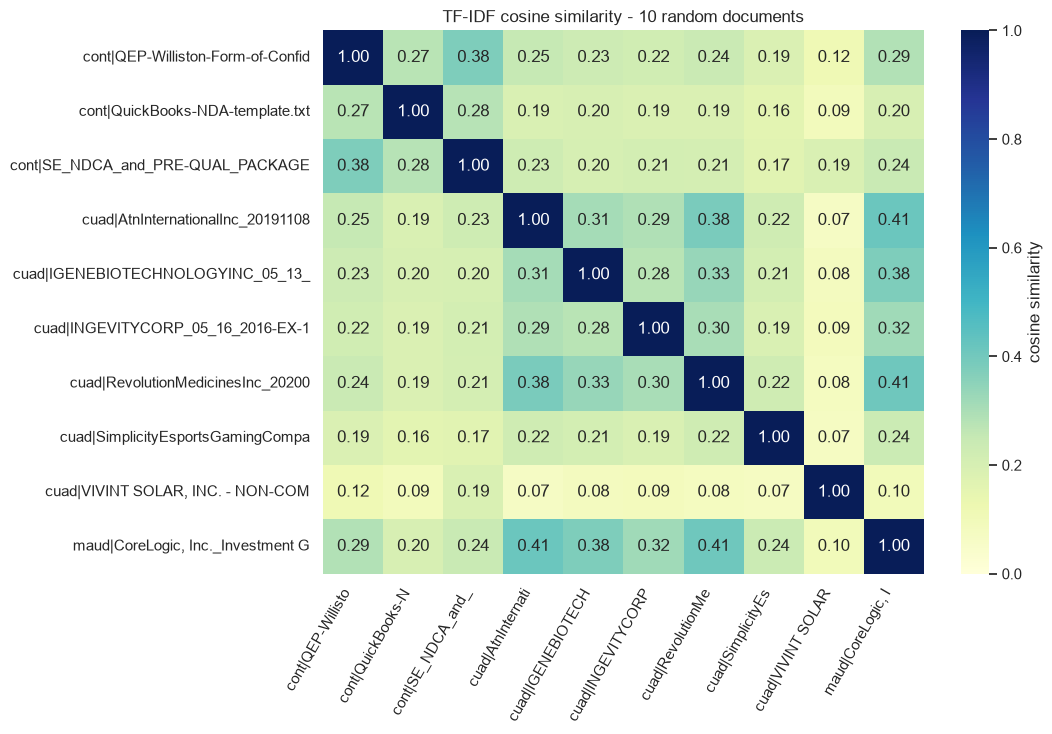

mean off-diagonal similarity = 0.23, max = 0.41


* The first ten documents are NDAs, with mean pairwise similarity 0.19.
* The random sample has mean pairwise similarity 0.23. Contracts share some vocabulary but differ in wording.
* TF-IDF similarity measures word usage. It does not establish legal equivalence or exact duplication.

In [ ]:
plot_sim(random_idx, "TF-IDF cosine similarity - 10 random documents")

first_scores = full_sim[:10, :10][~np.eye(10, dtype=bool)]
random_scores = full_sim[np.ix_(random_idx, random_idx)][~np.eye(10, dtype=bool)]
display(Markdown(
    f"* The first ten documents are NDAs, with mean pairwise similarity {first_scores.mean():.2f}.\n"
    f"* The random sample has mean pairwise similarity {random_scores.mean():.2f}. "
    "Contracts share some vocabulary but differ in wording.\n"
    "* TF-IDF similarity measures word usage. It does not establish legal equivalence or exact duplication."
))

## 4. Build the vector index

Create source-traceable chunks and document cards, embed them, and store them in Chroma. This stage sends document text to OpenAI and may incur charges.

In [ ]:
SEPARATORS = ["\n\n", "\n", ". ", "; ", ", ", " ", ""]

def make_chunks(docs, chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP):
    splitter = RecursiveCharacterTextSplitter(chunk_size=chunk_size, chunk_overlap=chunk_overlap,
                                              separators=SEPARATORS, add_start_index=True)
    out = []
    for doc in docs:
        fp = doc.metadata["file_path"]
        offsets = offset_maps[fp]
        for i, ch in enumerate(splitter.split_documents([doc])):
            s = ch.metadata.pop("start_index")
            e = s + len(ch.page_content)
            ch.metadata.update(chunk_id=f"{fp}::{i}", chunk_index=i,
                               start=int(offsets[s]), end=int(offsets[e - 1]) + 1)
            out.append(ch)
    return out

chunks = make_chunks(clean_documents)
chunk_df = pd.DataFrame([{**c.metadata, "chunk_chars": len(c.page_content)} for c in chunks])
print(f"{len(chunks):,} chunks created from {len(clean_documents)} documents")
display(chunk_df.groupby("category").agg(chunks=("chunk_id", "count"), mean_chunk_chars=("chunk_chars", "mean"),
                                         chunks_per_doc=("file_path", lambda s: len(s) / s.nunique())).round(1))

def pretty_title(file_name: str) -> str:
    return re.sub(r"[_]+", " ", file_name.removesuffix(".txt").replace("%20", " ")).strip()

doc_cards = [Document(page_content=f"{pretty_title(d.metadata['file_name'])}\n{d.page_content[:1500]}",
                      metadata={"file_path": d.metadata["file_path"], "category": d.metadata["category"],
                                "title": pretty_title(d.metadata["file_name"])})
             for d in clean_documents]
for c in chunks:
    c.metadata["title"] = pretty_title(c.metadata["file_name"])

display(Markdown(
    "* Recursive splitting prefers paragraph and sentence boundaries, "
    "with a maximum chunk size of 1,500 characters and a 200-character overlap.\n"
    "* These settings limit context length while allowing nearby text to remain together. "
    "Long clauses may still cross chunk boundaries.\n"
    "* Each chunk retains its original character span. "
    "A card containing the file name and first 1,500 characters supports contract selection."
))

63,914 chunks created from 644 documents


,chunks,mean_chunk_chars,chunks_per_doc
category,,,
contractnli,893,1125.9,9.6
cuad,20785,1072.4,48.2
maud,42192,958.3,360.6
privacy_qa,44,1353.8,14.7


* Recursive splitting prefers paragraph and sentence boundaries, with a maximum chunk size of 1,500 characters and a 200-character overlap.
* These settings limit context length while allowing nearby text to remain together. Long clauses may still cross chunk boundaries.
* Each chunk retains its original character span. A card containing the file name and first 1,500 characters supports contract selection.

In [ ]:
load_dotenv(BASE_DIR / ".env")
assert os.getenv("OPENAI_API_KEY"), "Please set OPENAI_API_KEY in a .env file or as an environment variable"
print("OpenAI API key loaded:", bool(os.getenv("OPENAI_API_KEY")))

OpenAI API key loaded: True


In [ ]:
embedding_fn = OpenAIEmbeddings(model=EMBEDDING_MODEL,
                                chunk_size=500,
                                max_retries=10)

vec = embedding_fn.embed_query("Which law governs this agreement?")
print(f"Embedding model: {EMBEDDING_MODEL} | dimension: {len(vec)} | L2 norm: {np.linalg.norm(vec):.3f}")

display(Markdown(
    "* The pipeline uses text-embedding-3-small for both document and query vectors.\n"
    "* This model integrates with the chosen OpenAI and Chroma components "
    "and produces 1,536-dimensional vectors."
))

Embedding model: text-embedding-3-small | dimension: 1536 | L2 norm: 0.999


* The pipeline uses text-embedding-3-small for both document and query vectors.
* This model integrates with the chosen OpenAI and Chroma components and produces 1,536-dimensional vectors.

In [ ]:
CHROMA_DIR.mkdir(exist_ok=True)

def add_documents_resumable(store: Chroma, docs, ids, batch_size=1000):
    """Add documents in batches and skip stored IDs for this fixed dataset."""
    existing = set(store.get(include=[])["ids"])
    pending = [(d, i) for d, i in zip(docs, ids) if i not in existing]
    print(f"[{store._collection.name}] already stored: {len(existing):,} | to embed: {len(pending):,}")
    t0 = time.time()
    for b in range(0, len(pending), batch_size):
        batch = pending[b:b + batch_size]
        store.add_documents([d for d, _ in batch], ids=[i for _, i in batch])
        done = b + len(batch)
        print(f"  {done:,}/{len(pending):,} embedded ({time.time() - t0:.0f}s)")
    return store

chunk_db = Chroma(collection_name="legal_chunks", embedding_function=embedding_fn, persist_directory=str(CHROMA_DIR))
card_db = Chroma(collection_name="legal_doc_cards", embedding_function=embedding_fn, persist_directory=str(CHROMA_DIR))

add_documents_resumable(card_db, doc_cards, [c.metadata["file_path"] for c in doc_cards])
add_documents_resumable(chunk_db, chunks, [c.metadata["chunk_id"] for c in chunks])

print(f"\nVector DB persisted at: {CHROMA_DIR.relative_to(BASE_DIR)}")
print(f"  legal_chunks   : {chunk_db._collection.count():,} vectors")
print(f"  legal_doc_cards: {card_db._collection.count():,} vectors")

display(Markdown(
    "* Chroma stores vectors locally and supports filtering by source file.\n"
    "* Stored IDs are reused for this fixed dataset, avoiding repeated document embedding."
))

[legal_doc_cards] already stored: 644 | to embed: 0


[legal_chunks] already stored: 63,914 | to embed: 0

Vector DB persisted at: chroma_legal_db
  legal_chunks   : 63,914 vectors
  legal_doc_cards: 644 vectors


* Chroma stores vectors locally and supports filtering by source file.
* Stored IDs are reused for this fixed dataset, avoiding repeated document embedding.

## 5. Retrieve evidence and generate answers

Route each question to one contract, then search only that contract's clauses. The model answers from those excerpts or abstains.

In [ ]:
def split_query(query: str):
    """Separate the contract description from the legal question."""
    prefix, question = query.split(";", 1)
    return prefix.strip(), question.strip()

def route_document(prefix: str):
    """Match the contract description against the document cards."""
    match = card_db.similarity_search(prefix, k=1)[0]
    return match.metadata["file_path"]

def routed_retrieve(query: str):
    """Select one contract and search its chunks using the legal question."""
    prefix, question = split_query(query)
    target = route_document(prefix)
    qvec = embedding_fn.embed_query(question)
    return chunk_db.similarity_search_by_vector(qvec, k=TOP_K, filter={"file_path": target})

def format_context(docs):
    return "\n\n".join(f"[Source {i}] {d.metadata['title']}\nFile: {d.metadata['file_path']}\nCharacters: {d.metadata['start']}-{d.metadata['end']}\n{d.page_content}"
                       for i, d in enumerate(docs, 1))

ABSTENTION = "The provided excerpts do not contain this information."

SYSTEM_PROMPT = """Answer legal document questions using only the numbered excerpts.
Follow these rules:
1. Check the source title, file name and excerpt text against the contract named in the question. Retrieved excerpts may come from a different contract. Do not use evidence from another contract.
2. Give a direct answer only when a clause from the requested contract supports it. Include any conditions or exceptions stated in that clause.
3. Answer Yes or No only when a clause directly supports that conclusion about the action or obligation asked about. Do not infer a prohibition from missing permission, or permission from a missing prohibition. A clause about a different subject is not evidence.
4. Quote the supporting text exactly and cite it as [Source n]. Each conclusion must be supported by its cited quote.
5. If the excerpts do not establish the requested contract or do not support an answer, respond only with: The provided excerpts do not contain this information.
6. Missing evidence in the excerpts does not mean the full contract lacks the relevant clause.
7. Use complete sentences. Do not use em dashes in your own wording. Do not use outside knowledge or give legal advice."""

prompt = ChatPromptTemplate.from_messages([("system", SYSTEM_PROMPT),
                                           ("human", "Question: {question}\n\nContext excerpts:\n{context}\n\nAnswer:")])
llm = ChatOpenAI(model=LLM_MODEL, temperature=0, max_tokens=700, max_retries=6)

generate = (RunnableLambda(lambda x: {"question": x["question"], "context": format_context(x["source_documents"])})
            | prompt | llm | StrOutputParser())

def answer_or_abstain(result):
    return generate.invoke(result) if result["source_documents"] else ABSTENTION

rag_chain = (RunnableParallel(question=RunnablePassthrough(), source_documents=RunnableLambda(routed_retrieve))
             | RunnablePassthrough.assign(answer=RunnableLambda(answer_or_abstain)))
print("RAG chain:", " -> ".join(type(s).__name__ for s in rag_chain.steps))

display(Markdown(
    "* Benchmark questions use `Consider <contract>; <question>`. "
    "The retriever selects a contract before clause search.\n"
    "* Clause search is limited to the routed file. If no excerpts are found, the chain abstains without calling the model.\n"
    "* The prompt requires a quoted clause for every conclusion. A routing error still leads to evidence from the wrong contract."
))

RAG chain: RunnableParallel -> RunnableAssign


* Benchmark questions use `Consider <contract>; <question>`. The retriever selects a contract before clause search.
* Clause search is limited to the routed file. If no excerpts are found, the chain abstains without calling the model.
* The prompt requires a quoted clause for every conclusion. A routing error still leads to evidence from the wrong contract.

In [ ]:
def answer_question(question: str) -> dict:
    """Run the RAG chain and return the answer with its sources."""
    result = rag_chain.invoke(question)
    sources = [{"source": i, "file_path": d.metadata["file_path"], "span": (d.metadata["start"], d.metadata["end"])}
               for i, d in enumerate(result["source_documents"], 1)]
    return {"question": question, "answer": result["answer"], "sources": sources,
            "source_documents": result["source_documents"]}

## 6. Load benchmark questions

Extract questions and supporting snippets, then identify questions with available source files.

In [ ]:
bench_raw = {p.stem: json.loads(p.read_text(encoding="utf-8"))["tests"]
             for p in sorted(BENCH_DIR.glob("*.json"))}
for tests in bench_raw.values():
    for test in tests:
        for snippet in test["snippets"]:
            snippet["file_path"] = nfc(snippet["file_path"])

records = []
for name, tests in bench_raw.items():
    for i, t in enumerate(tests):
        files = sorted({s["file_path"] for s in t["snippets"]})
        records.append({"qid": f"{name}_{i}", "benchmark": name, "query": t["query"],
                        "ground_truth": "\n".join(s["answer"] for s in t["snippets"]),
                        "snippets": t["snippets"], "gold_file": files[0], "n_snippets": len(t["snippets"]),
                        "answerable": all(f in clean_texts for f in files)})
qa_df = pd.DataFrame(records)
questions, ground_truths = qa_df["query"].tolist(), qa_df["ground_truth"].tolist()
print(f"{len(questions):,} questions and {len(ground_truths):,} ground-truth answers extracted")
display(qa_df.groupby("benchmark").agg(questions=("qid", "count"), answerable=("answerable", "sum"),
                                       mean_snippets=("n_snippets", "mean")).round(2))

eval_df = qa_df[qa_df.answerable].reset_index(drop=True)
print(f"Answerable questions used for evaluation: {len(eval_df):,} "
      f"({len(qa_df) - len(eval_df)} dropped because their source file is not in the corpus)")

display(Markdown(
    "* All benchmark questions and reference snippets are extracted before filtering.\n"
    "* Evaluation excludes questions whose source files are unavailable. "
    "Unicode path normalisation prevents false missing-file matches.\n"
    "* The privacy-policy benchmark is absent, so those documents are not evaluated."
))

6,695 questions and 6,695 ground-truth answers extracted


,questions,answerable,mean_snippets
benchmark,,,
contractnli,977,962,1.42
cuad,4042,3753,1.55
maud,1676,1318,1.69


Answerable questions used for evaluation: 6,033 (662 dropped because their source file is not in the corpus)


* All benchmark questions and reference snippets are extracted before filtering.
* Evaluation excludes questions whose source files are unavailable. Unicode path normalisation prevents false missing-file matches.
* The privacy-policy benchmark is absent, so those documents are not evaluated.

## 7. Ask a question

The example answers the first benchmark question with an available source document.

In [ ]:
question = eval_df.iloc[0]["query"]
example = answer_question(question)
print(f"Question: {question}\n")
print(f"Answer: {example['answer']}\n")
for s in example["sources"]:
    print(f"[Source {s['source']}] {s['file_path']}, characters {s['span'][0]}-{s['span'][1]}")

Question: Consider the Non-Disclosure Agreement between CopAcc and ToP Mentors; Does the document indicate that the Agreement does not grant the Receiving Party any rights to the Confidential Information?

Answer: Yes, the document indicates that the Agreement does not grant the Receiving Party any rights to the Confidential Information. The relevant clause states, "Mentor shall not have any right, license, title or interest in or to any Confidential Information, except the limited right to review, assess and help develop such Confidential Information in connection with the Copernicus Accelerator 2017" [Source 2].

[Source 1] contractnli/CopAcc_NDA-and-ToP-Mentors_2.0_2017.txt, characters 8059-9377
[Source 2] contractnli/CopAcc_NDA-and-ToP-Mentors_2.0_2017.txt, characters 10540-11970
[Source 3] contractnli/CopAcc_NDA-and-ToP-Mentors_2.0_2017.txt, characters 9378-10729
[Source 4] contractnli/CopAcc_NDA-and-ToP-Mentors_2.0_2017.txt, characters 11964-13252
[Source 5] contractnli/CopAcc_ND

## 8. Evaluate retrieval and generation

Evaluate ten fixed-seed questions using two span-based retrieval metrics and four Ragas metrics. Saved tables and charts show the recorded run; this cell makes new API calls when executed.

In [ ]:
def retrieval_metrics(retrieved, snippets, k=TOP_K):
    """Calculate Hit Rate@k and reciprocal rank using source-span overlap."""
    relevant = [
        any(
            doc.metadata["file_path"] == snippet["file_path"]
            and doc.metadata["start"] < snippet["span"][1]
            and doc.metadata["end"] > snippet["span"][0]
            for snippet in snippets
        )
        for doc in retrieved[:k]
    ]
    first = next((i for i, match in enumerate(relevant) if match), None)
    return {
        "hit_rate": float(first is not None),
        "mrr": 0.0 if first is None else 1 / (first + 1),
    }

from openai import AsyncOpenAI
from ragas.llms import llm_factory
from ragas.embeddings import embedding_factory
from ragas.metrics.collections import Faithfulness, AnswerRelevancy, ContextPrecision, ContextRecall

judge_client = AsyncOpenAI()
ragas_llm = llm_factory(LLM_MODEL, client=judge_client)
ragas_emb = embedding_factory("openai", model=EMBEDDING_MODEL, client=judge_client)
RAGAS_METRICS = [
    Faithfulness(llm=ragas_llm),
    AnswerRelevancy(llm=ragas_llm, embeddings=ragas_emb),
    ContextPrecision(llm=ragas_llm),
    ContextRecall(llm=ragas_llm),
]

async def ragas_scores(samples):
    """Score responses and context, recording unavailable scores as missing."""
    semaphore = asyncio.Semaphore(8)

    async def score_one(i, metric):
        kwargs = {
            key: samples[i][key]
            for key in inspect.signature(metric.ascore).parameters
            if key in samples[i]
        }
        async with semaphore:
            try:
                score = await metric.ascore(**kwargs)
                return i, metric.name, float(score.value)
            except Exception as exc:
                print(f"{metric.name} failed on sample {i}: {type(exc).__name__}: {exc}")
                return i, metric.name, np.nan

    scores = await asyncio.gather(*[
        score_one(i, metric) for i in range(len(samples)) for metric in RAGAS_METRICS
    ])
    return pd.DataFrame(scores, columns=["i", "metric", "score"]).pivot(
        index="i", columns="metric", values="score"
    )

async def evaluate_rag_pipeline(sample_df):
    """Generate answers, then score retrieval and generation."""
    outputs = rag_chain.batch(sample_df["query"].tolist(), config={"max_concurrency": 5})
    samples = [
        {
            "user_input": query,
            "response": output["answer"],
            "retrieved_contexts": [doc.page_content for doc in output["source_documents"]],
            "reference": reference,
        }
        for query, output, reference in zip(
            sample_df["query"], outputs, sample_df["ground_truth"]
        )
    ]
    generation = await ragas_scores(samples)
    retrieval = pd.DataFrame([
        retrieval_metrics(output["source_documents"], snippets)
        for output, snippets in zip(outputs, sample_df["snippets"])
    ])
    results = pd.concat([
        sample_df[["qid", "benchmark"]].reset_index(drop=True),
        retrieval,
        generation.reset_index(drop=True),
    ], axis=1)
    results["answer"] = [output["answer"] for output in outputs]
    return results

display(Markdown(
    "* Hit Rate@5 records whether any retrieved chunk overlaps a reference span in the correct file. "
    "MRR@5 measures the rank of the first overlapping chunk.\n"
    "* Any positive overlap counts as a hit. "
    "These metrics do not measure full-clause recovery or answer accuracy.\n"
    "* Ragas measures faithfulness, answer relevancy, context precision and context recall "
    "using the excerpts supplied to the generator."
))

* Hit Rate@5 records whether any retrieved chunk overlaps a reference span in the correct file. MRR@5 measures the rank of the first overlapping chunk.
* Any positive overlap counts as a hit. These metrics do not measure full-clause recovery or answer accuracy.
* Ragas measures faithfulness, answer relevancy, context precision and context recall using the excerpts supplied to the generator.

,qid,benchmark,hit_rate,mrr,faithfulness,answer_relevancy,context_precision,context_recall
0,contractnli_344,contractnli,0.0,0.000,1.000,0.000,0.250,0.000
1,contractnli_381,contractnli,1.0,1.000,1.000,0.597,1.000,1.000
2,contractnli_351,contractnli,1.0,0.200,1.000,0.710,1.000,1.000
3,cuad_2307,cuad,1.0,0.333,1.000,0.745,0.583,1.000
4,cuad_1100,cuad,1.0,0.200,0.667,0.577,0.200,1.000
5,cuad_3537,cuad,1.0,1.000,0.000,0.000,1.000,1.000
6,cuad_457,cuad,1.0,1.000,1.000,0.936,1.000,1.000
7,maud_862,maud,1.0,1.000,1.000,0.430,1.000,1.000
8,maud_1202,maud,1.0,1.000,0.500,0.629,0.533,0.714
9,maud_773,maud,1.0,0.500,0.857,0.625,1.000,1.000


,mean_score,valid_samples
hit_rate,0.900,10.0
mrr,0.623,10.0
faithfulness,0.802,10.0
answer_relevancy,0.525,10.0
context_precision,0.757,10.0
context_recall,0.871,10.0


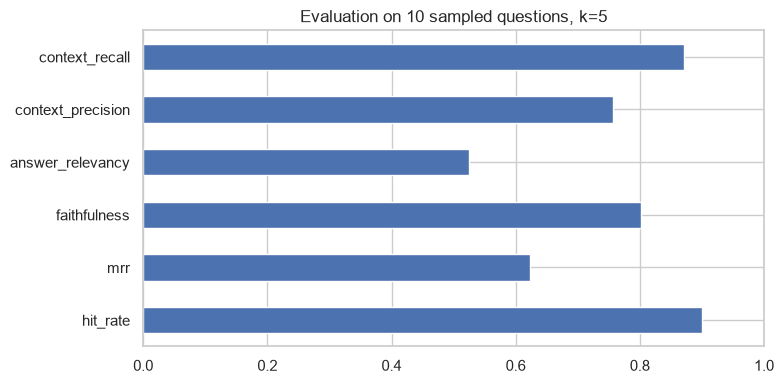

* Retrieved chunks overlap a reference span for 9 of 10 questions. The model abstains on 2 questions.
* At least 1 of 10 questions had a retrieval hit but no answer. A span overlap may still provide insufficient evidence.
* Context recall is 0.871, while answer relevancy is 0.525. Retrieved evidence does not always produce a responsive answer.
* Faithfulness measures support for generated claims. An abstention can score well even when retrieval misses the answer.

In [ ]:
# Sample three NDA, four CUAD and three MAUD questions with a fixed seed.
sample_df = pd.concat([
    eval_df[eval_df.benchmark == name].sample(count, random_state=SEED)
    for name, count in [("contractnli", 3), ("cuad", 4), ("maud", 3)]
]).reset_index(drop=True)
results = await evaluate_rag_pipeline(sample_df)
score_cols = [
    "hit_rate", "mrr", "faithfulness", "answer_relevancy", "context_precision", "context_recall"
]
display(results[["qid", "benchmark", *score_cols]].round(3))
evaluation_summary = results[score_cols].agg(["mean", "count"]).T
evaluation_summary.columns = ["mean_score", "valid_samples"]
display(evaluation_summary.round(3))

evaluation_summary["mean_score"].plot.barh(figsize=(8, 4))
plt.title(f"Evaluation on {len(sample_df)} sampled questions, k={TOP_K}")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

misses = int((results.hit_rate == 0).sum())
abstentions = int((results.answer == ABSTENTION).sum())
min_unanswered_hits = max(0, abstentions - misses)
means = evaluation_summary["mean_score"]
display(Markdown(
    f"* Retrieved chunks overlap a reference span for {len(results) - misses} of {len(results)} questions. "
    f"The model abstains on {abstentions} questions.\n"
    f"* At least {min_unanswered_hits} of {len(results)} questions had a retrieval hit but no answer. "
    "A span overlap may still provide insufficient evidence.\n"
    f"* Context recall is {means['context_recall']:.3f}, while answer relevancy is {means['answer_relevancy']:.3f}. "
    "Retrieved evidence does not always produce a responsive answer.\n"
    "* Faithfulness measures support for generated claims. An abstention can score well even when retrieval misses the answer."
))

## Findings

* **Data:** The corpus contains 644 legal documents with widely varying lengths. Of 6,695 benchmark questions, 6,033 have available source documents.
* **Preparation:** Cleaning preserves legal wording for retrieval and removes stop words only for EDA. Documents are split into 1,500-character chunks with 200-character overlap and original source positions.
* **Model pipeline:** LangChain connects `text-embedding-3-small`, a persisted Chroma vector database and `gpt-4o-mini` for answer generation.
* **RAG process:** Document cards identify the likely contract before clause retrieval. The model uses the selected excerpts to answer with quotes and source citations, or abstains when evidence is insufficient.
* **Results:** On ten evaluated questions, Hit Rate@5 is 0.900 and MRR@5 is 0.623. Ragas faithfulness is 0.802, context recall is 0.871 and answer relevancy is 0.525.
* **Learning:** Retrieval found overlapping reference text for nine questions, but the model abstained twice. At least one retrieval hit therefore did not produce an answer. The six-month notice-period answer shows how a specific clause supports a useful response; the lower answer relevancy highlights the need to improve clause selection and how retrieved evidence is used.